# Notebook 1 — From Pixels to Indices
## Nouakchott Built-up Analysis with Sentinel-2

**What this notebook does:**
1. Display raw Sentinel-2 imagery over Nouakchott
2. Overlay moughataa boundaries
3. Show how individual spectral bands differ between land cover types
4. Compute built-up indices pixel by pixel and visualize them
5. Aggregate to zonal statistics per moughataa
6. Compare 2016 vs 2024 to show urban expansion

---

## 0. Setup & Imports

In [1]:
import ee
import geopandas as gpd
import pandas as pd
import numpy as np
import json
import os
import requests
from io import BytesIO
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.gridspec as gridspec

import folium
from folium import GeoJson, GeoJsonTooltip
import branca.colormap as cm

# Initialize GEE
ee.Initialize(project=os.environ.get('GEE_PROJECT'))
print('✓ GEE initialized')

✓ GEE initialized


## 1. Load Nouakchott Boundaries
We extract only Nouakchott's 9 moughataat from the national shapefile.

In [2]:
# ── Load shapefile ──────────────────────────────────────────
SHP_PATH = '/data/polygons/mrt_admin2.shp'

gdf_all = gpd.read_file(SHP_PATH)
if gdf_all.crs.to_epsg() != 4326:
    gdf_all = gdf_all.to_crs(epsg=4326)

# Filter Nouakchott (3 wilayas)
nouakchott_wilayas = ['Nouakchott Nord', 'Nouakchott Ouest', 'Nouakchott Sud']
gdf = gdf_all[gdf_all['adm1_name'].isin(nouakchott_wilayas)].copy()
gdf = gdf.reset_index(drop=True)

print(f'Nouakchott moughataat: {len(gdf)}')
print(gdf[['adm2_name', 'adm1_name', 'area_sqkm']].to_string())

Nouakchott moughataat: 9
       adm2_name         adm1_name   area_sqkm
0     Toujounine   Nouakchott Nord   55.721617
1       Dar Naïm   Nouakchott Nord   42.834226
2       Teyarett   Nouakchott Nord  120.124261
3         Sebkha  Nouakchott Ouest   15.809840
4           Ksar  Nouakchott Ouest  273.483340
5  Tevragh Zeina  Nouakchott Ouest  334.978331
6         Arafat    Nouakchott Sud   15.113742
7        El Mina    Nouakchott Sud  152.822956
8           Riad    Nouakchott Sud  173.867708


In [3]:
# ── Convert to GEE geometries ───────────────────────────────
def gdf_to_ee_fc(gdf, name_col='adm2_name'):
    """Convert GeoDataFrame to EE FeatureCollection."""
    features = []
    for _, row in gdf.iterrows():
        geom_json = json.loads(
            gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json()
        )
        geom_ee = ee.Geometry(geom_json['features'][0]['geometry'])
        feat = ee.Feature(geom_ee, {name_col: row[name_col]})
        features.append(feat)
    return ee.FeatureCollection(features)

fc_nouakchott = gdf_to_ee_fc(gdf)
region_nouakchott = fc_nouakchott.geometry().bounds()

print('✓ GEE FeatureCollection ready')

✓ GEE FeatureCollection ready


## 2. Raw Sentinel-2 Imagery
### 2.1 True Color RGB — What the satellite actually sees

In [4]:
def get_s2_composite(year, month, region, max_cloud=20):
    """Get a clean Sentinel-2 monthly median composite."""
    start = ee.Date.fromYMD(year, month, 1)
    end   = start.advance(3, 'month')  # 3-month window for cleaner composite

    def mask_clouds(img):
        scl = img.select('SCL')
        mask = (scl.neq(3).And(scl.neq(8)).And(scl.neq(9))
                   .And(scl.neq(10)).And(scl.neq(11)))
        # Dust filter
        b1 = img.select('B1').toFloat()
        b2 = img.select('B2').toFloat()
        dust_mask = b1.divide(b2.add(1e-6)).lt(0.85)
        return img.updateMask(mask.And(dust_mask)).divide(10000)

    col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
             .filterDate(start, end)
             .filterBounds(region)
             .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', max_cloud))
             .map(mask_clouds))

    return col.median()


def get_thumbnail(image, region, bands, vis_min, vis_max,
                  dimensions=800, gamma=1.4):
    """Fetch image thumbnail as PIL Image via GEE URL."""
    url = image.getThumbURL({
        'bands'     : bands,
        'min'       : vis_min,
        'max'       : vis_max,
        'gamma'     : gamma,
        'region'    : region,
        'dimensions': dimensions,
        'format'    : 'png'
    })
    response = requests.get(url, timeout=60)
    return Image.open(BytesIO(response.content))


# Get composite for a dry season month (low haze)
print('Fetching Sentinel-2 composite... (takes ~30s)')
composite_2024 = get_s2_composite(2024, 1, region_nouakchott)
composite_2016 = get_s2_composite(2016, 1, region_nouakchott)

# True color thumbnails
rgb_2024 = get_thumbnail(composite_2024, region_nouakchott,
                          bands=['B4','B3','B2'],
                          vis_min=0.02, vis_max=0.22)
rgb_2016 = get_thumbnail(composite_2016, region_nouakchott,
                          bands=['B4','B3','B2'],
                          vis_min=0.02, vis_max=0.22)
print('✓ Thumbnails ready')

Fetching Sentinel-2 composite... (takes ~30s)
✓ Thumbnails ready


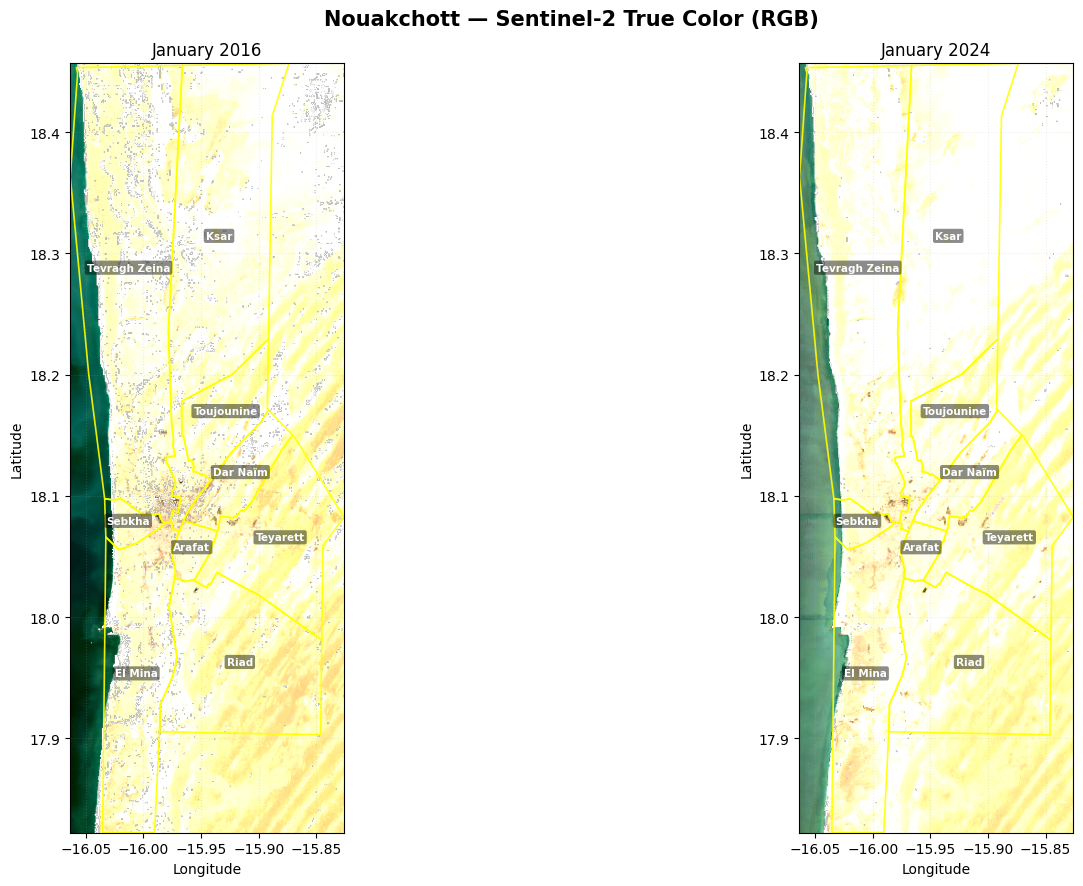

→ Built-up areas appear grey/beige, desert is sandy/brown


In [6]:
# ── Plot RGB with polygon boundaries ───────────────────────
bounds = gdf.total_bounds  # [minx, miny, maxx, maxy]

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fig.suptitle('Nouakchott — Sentinel-2 True Color (RGB)',
             fontsize=15, fontweight='bold')

for ax, img, year in zip(axes, [rgb_2016, rgb_2024], [2016, 2024]):
    ax.imshow(img, extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
              origin='upper', aspect='equal')

    # Draw moughataa boundaries
    gdf.boundary.plot(ax=ax, color='yellow', linewidth=1.2, alpha=0.9)

    # Label each moughataa
    for _, row in gdf.iterrows():
        cx = row.geometry.centroid.x
        cy = row.geometry.centroid.y
        ax.annotate(row['adm2_name'], (cx, cy),
                    fontsize=7.5, color='white', ha='center',
                    fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2',
                              facecolor='black', alpha=0.45, linewidth=0))

    ax.set_title(f'January {year}', fontsize=12)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.grid(alpha=0.2, ls=':')

plt.tight_layout()
plt.savefig('/outputs/01_rgb_nouakchott.png', dpi=150, bbox_inches='tight')
plt.show()
print('→ Built-up areas appear grey/beige, desert is sandy/brown')

## 3. Spectral Bands — Why SWIR Detects Built-up Areas
Different surfaces reflect light differently across the spectrum.
Built-up areas (concrete, metal roofs) reflect strongly in SWIR1 (B11).

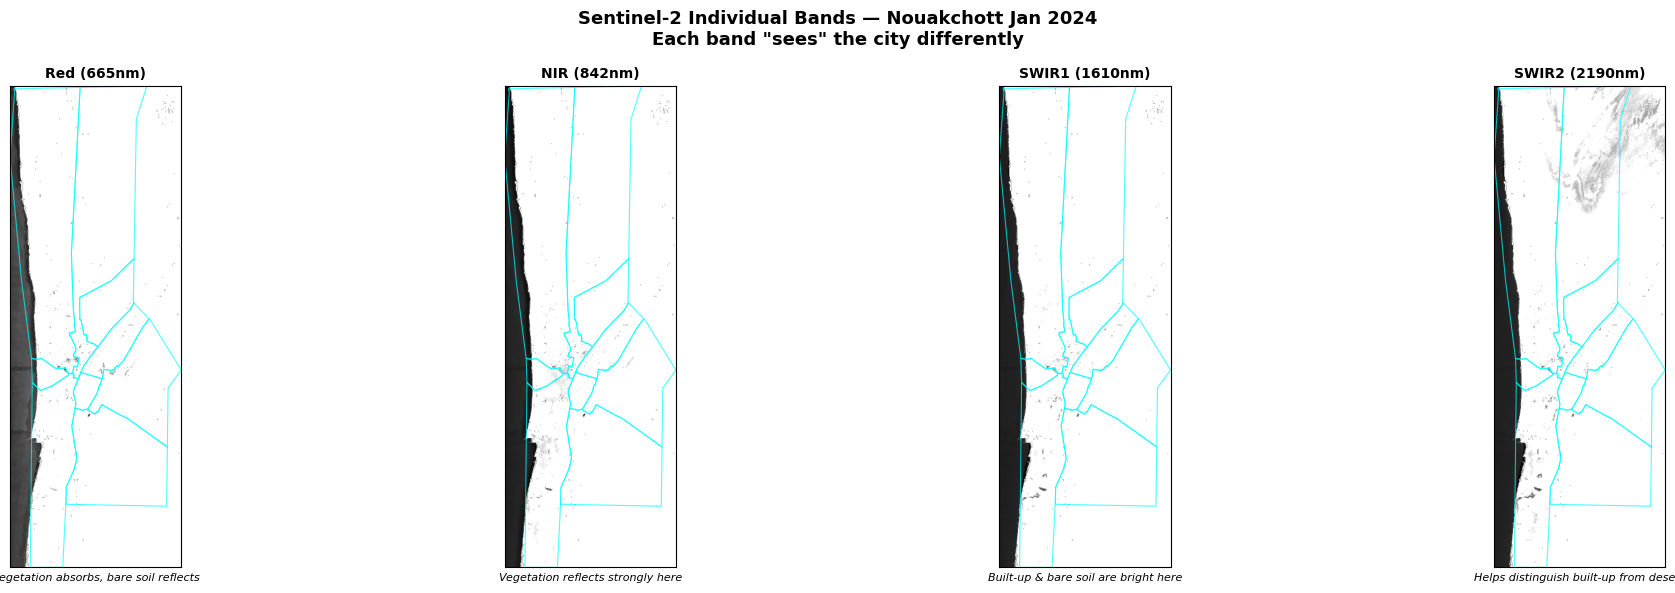

In [7]:
# ── Show individual bands for 2024 ─────────────────────────
band_configs = [
    ('B4',  'Red (665nm)',          'Reds',    0.0, 0.25,
     'Vegetation absorbs, bare soil reflects'),
    ('B8',  'NIR (842nm)',          'YlGn',    0.0, 0.35,
     'Vegetation reflects strongly here'),
    ('B11', 'SWIR1 (1610nm)',       'hot_r',   0.0, 0.35,
     'Built-up & bare soil are bright here'),
    ('B12', 'SWIR2 (2190nm)',       'copper',  0.0, 0.30,
     'Helps distinguish built-up from desert'),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
fig.suptitle('Sentinel-2 Individual Bands — Nouakchott Jan 2024\n'
             'Each band "sees" the city differently',
             fontsize=13, fontweight='bold')

for ax, (band, label, cmap, vmin, vmax, note) in zip(axes, band_configs):
    thumb = get_thumbnail(composite_2024, region_nouakchott,
                          bands=[band, band, band],
                          vis_min=vmin, vis_max=vmax, gamma=1.0)

    ax.imshow(thumb, extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
              origin='upper', cmap=cmap, aspect='equal')
    gdf.boundary.plot(ax=ax, color='cyan', linewidth=0.8, alpha=0.7)

    ax.set_title(f'{label}', fontsize=10, fontweight='bold')
    ax.set_xlabel(note, fontsize=8, style='italic')
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig('/outputs/02_bands_nouakchott.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Built-up Index Rasters
### Computing BAEI and NDBI pixel by pixel

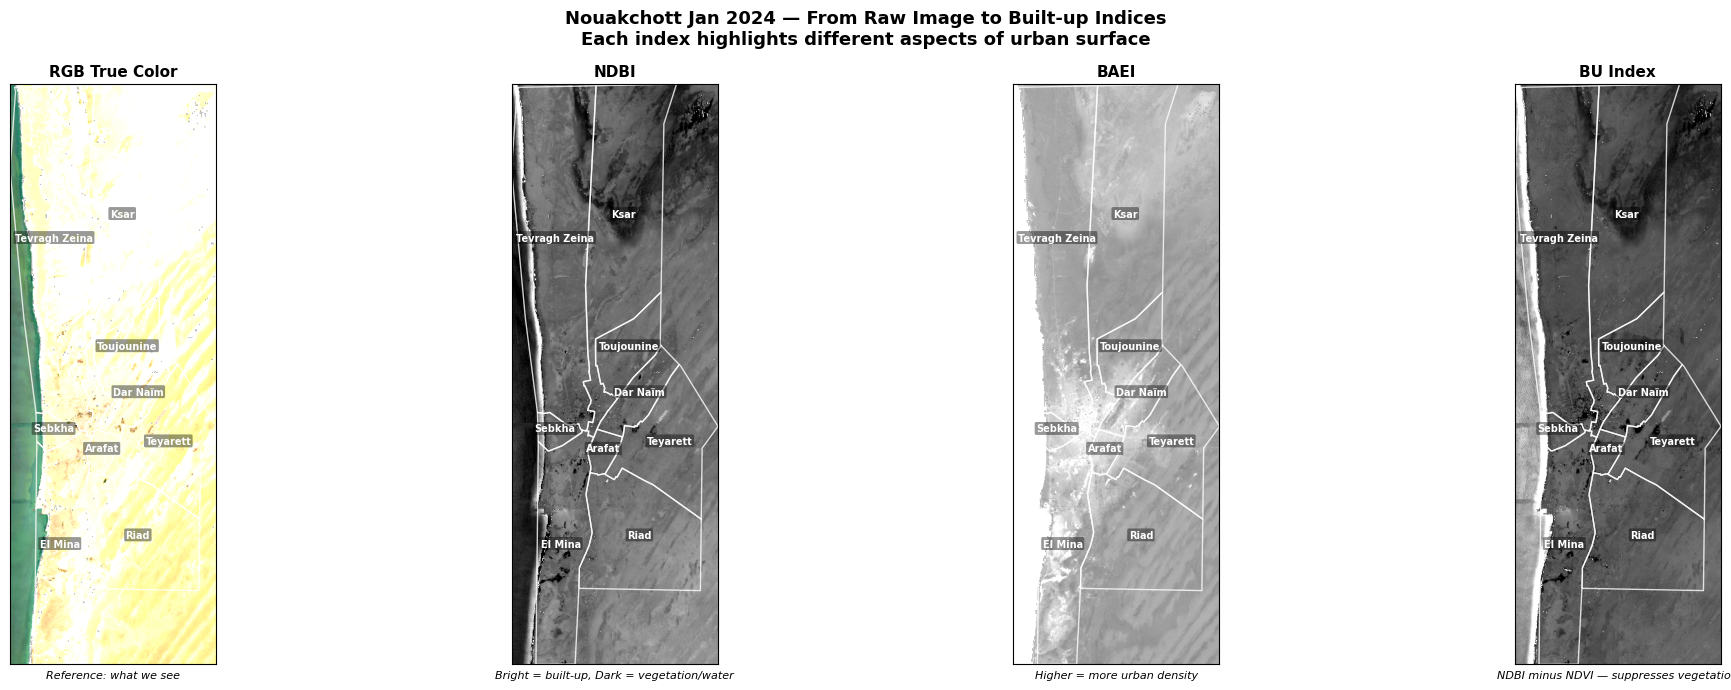

In [8]:
def compute_indices_image(image):
    """Compute indices on a GEE image for visualization."""
    b2  = image.select('B2')   # Blue
    b3  = image.select('B3')   # Green
    b4  = image.select('B4')   # Red
    b8  = image.select('B8')   # NIR
    b11 = image.select('B11')  # SWIR1
    b12 = image.select('B12')  # SWIR2
    eps = 1e-10

    ndbi  = b11.subtract(b8).divide(b11.add(b8).add(eps)).rename('ndbi')
    ndvi  = b8.subtract(b4).divide(b8.add(b4).add(eps))
    bu    = ndbi.subtract(ndvi).rename('bu')
    baei  = b4.add(0.3).divide(b3.add(b11).add(eps)).rename('baei')
    brba  = b4.divide(b11.add(eps)).rename('brba')
    vbish = b2.divide(b12.add(eps)).rename('vbish')

    return image.addBands([ndbi, bu, baei, brba, vbish])


img_with_indices = compute_indices_image(composite_2024)

# ── Visualize indices side by side ─────────────────────────
index_configs = [
    ('B4','B3','B2', 'RGB True Color',   0.02, 0.22, 1.4,
     'Reference: what we see'),
    ('ndbi','ndbi','ndbi', 'NDBI',        -0.1, 0.3,  1.0,
     'Bright = built-up, Dark = vegetation/water'),
    ('baei','baei','baei', 'BAEI',        0.4,  1.0,  1.0,
     'Higher = more urban density'),
    ('bu','bu','bu',       'BU Index',   -0.2, 0.3,  1.0,
     'NDBI minus NDVI — suppresses vegetation'),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 7))
fig.suptitle('Nouakchott Jan 2024 — From Raw Image to Built-up Indices\n'
             'Each index highlights different aspects of urban surface',
             fontsize=13, fontweight='bold')

cmaps = [None, 'RdYlGn_r', 'YlOrRd', 'RdYlGn_r']

for ax, (b1,b2,b3, title, vmin, vmax, gamma, note), cmap in \
        zip(axes, index_configs, cmaps):

    src_img = composite_2024 if title == 'RGB True Color' \
              else img_with_indices

    thumb = get_thumbnail(src_img, region_nouakchott,
                          bands=[b1,b2,b3],
                          vis_min=vmin, vis_max=vmax, gamma=gamma)

    ax.imshow(thumb, extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
              origin='upper', aspect='equal')
    gdf.boundary.plot(ax=ax, color='white', linewidth=1.0, alpha=0.8)

    # Label moughataas
    for _, row in gdf.iterrows():
        ax.annotate(row['adm2_name'],
                    (row.geometry.centroid.x, row.geometry.centroid.y),
                    fontsize=7, color='white', ha='center',
                    fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.15',
                              facecolor='black', alpha=0.4, linewidth=0))

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(note, fontsize=8, style='italic')
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig('/outputs/03_indices_raster_nouakchott.png',
            dpi=150, bbox_inches='tight')
plt.show()

## 5. Zonal Statistics — Aggregating Pixels to Moughataa Level
Now we reduce all pixels within each polygon to a single mean value.

In [9]:
def extract_zonal_stats_for_map(image, gdf, name_col='adm2_name'):
    """Extract mean of each index per moughataa polygon."""
    indices = ['ndbi', 'baei', 'bu', 'vbish']
    results = []

    for _, row in gdf.iterrows():
        geom_json = json.loads(
            gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json()
        )
        geom_ee = ee.Geometry(geom_json['features'][0]['geometry'])

        vals = image.select(indices).reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geom_ee,
            scale=10,
            maxPixels=1e10,
            bestEffort=True
        ).getInfo()

        entry = {name_col: row[name_col], 'adm1_name': row['adm1_name']}
        entry.update(vals)
        results.append(entry)

    return pd.DataFrame(results)


print('Extracting zonal stats for 2016 and 2024...')
img_2024 = compute_indices_image(composite_2024)
img_2016 = compute_indices_image(composite_2016)

stats_2024 = extract_zonal_stats_for_map(img_2024, gdf)
stats_2016 = extract_zonal_stats_for_map(img_2016, gdf)

# Merge with geodataframe
gdf_2024 = gdf.merge(stats_2024, on='adm2_name')
gdf_2016 = gdf.merge(stats_2016, on='adm2_name')

print('\n── BAEI mean per moughataa ────────────────────────')
comparison = pd.DataFrame({
    'moughataa': stats_2024['adm2_name'],
    'wilaya'   : stats_2024['adm1_name'],
    'baei_2016': stats_2016['baei'].round(4),
    'baei_2024': stats_2024['baei'].round(4),
})
comparison['change'] = (comparison['baei_2024'] - comparison['baei_2016']).round(4)
print(comparison.sort_values('change', ascending=False).to_string(index=False))

Extracting zonal stats for 2016 and 2024...

── BAEI mean per moughataa ────────────────────────
    moughataa           wilaya  baei_2016  baei_2024  change
   Toujounine  Nouakchott Nord     0.7965     0.8074  0.0109
       Arafat   Nouakchott Sud     0.9012     0.9116  0.0104
     Dar Naïm  Nouakchott Nord     0.8407     0.8467  0.0060
     Teyarett  Nouakchott Nord     0.8052     0.8103  0.0051
         Riad   Nouakchott Sud     0.8012     0.7959 -0.0053
         Ksar Nouakchott Ouest     0.8268     0.8206 -0.0062
      El Mina   Nouakchott Sud     1.1723     0.9867 -0.1856
Tevragh Zeina Nouakchott Ouest     1.2644     1.0360 -0.2284
       Sebkha Nouakchott Ouest     1.7864     1.1270 -0.6594


## 6. Choropleth Maps — BAEI per Moughataa

/tmp/ipykernel_25/3704050047.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


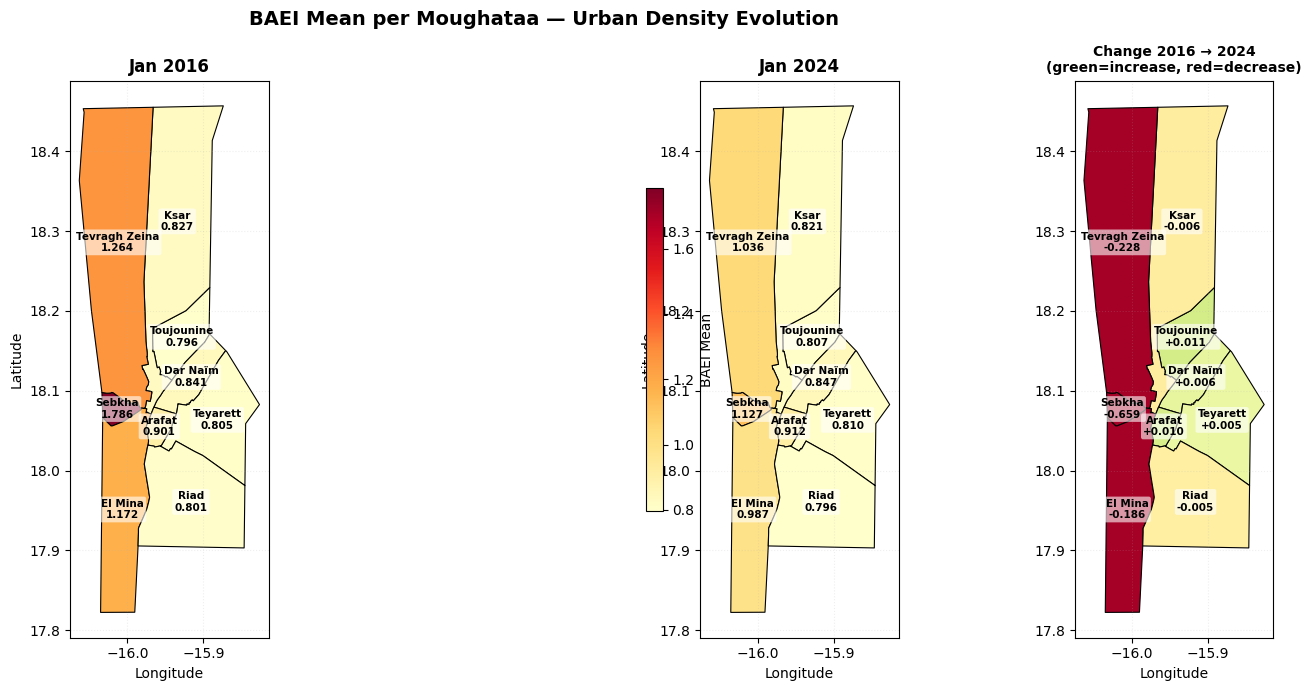

In [10]:
# ── Static choropleth: 2016 vs 2024 ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 7),
                          gridspec_kw={'width_ratios': [1, 1, 1]})
fig.suptitle('BAEI Mean per Moughataa — Urban Density Evolution',
             fontsize=14, fontweight='bold')

vmin = min(gdf_2016['baei'].min(), gdf_2024['baei'].min())
vmax = max(gdf_2016['baei'].max(), gdf_2024['baei'].max())

cmap = plt.cm.YlOrRd

for ax, gdf_plot, year in zip(axes[:2],
                               [gdf_2016, gdf_2024],
                               ['Jan 2016', 'Jan 2024']):
    gdf_plot.plot(column='baei', ax=ax, cmap=cmap,
                  vmin=vmin, vmax=vmax,
                  edgecolor='black', linewidth=0.8)

    for _, row in gdf_plot.iterrows():
        cx = row.geometry.centroid.x
        cy = row.geometry.centroid.y
        ax.annotate(f"{row['adm2_name']}\n{row['baei']:.3f}",
                    (cx, cy), fontsize=7.5, ha='center', va='center',
                    fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2',
                              facecolor='white', alpha=0.6, linewidth=0))

    ax.set_title(year, fontsize=12, fontweight='bold')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.grid(alpha=0.2, ls=':')

# Third panel: change map
ax = axes[2]
gdf_change = gdf_2024.copy()
gdf_change['baei_change'] = gdf_2024['baei'].values - gdf_2016['baei'].values

gdf_change.plot(column='baei_change', ax=ax,
                cmap='RdYlGn',
                vmin=-0.05, vmax=0.05,
                edgecolor='black', linewidth=0.8)

for _, row in gdf_change.iterrows():
    cx = row.geometry.centroid.x
    cy = row.geometry.centroid.y
    sign = '+' if row['baei_change'] > 0 else ''
    ax.annotate(f"{row['adm2_name']}\n{sign}{row['baei_change']:.3f}",
                (cx, cy), fontsize=7.5, ha='center', va='center',
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2',
                          facecolor='white', alpha=0.6, linewidth=0))

ax.set_title('Change 2016 → 2024\n(green=increase, red=decrease)',
             fontsize=10, fontweight='bold')
ax.set_xlabel('Longitude')
ax.grid(alpha=0.2, ls=':')

# Shared colorbar
sm = plt.cm.ScalarMappable(cmap=cmap,
                            norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
fig.colorbar(sm, ax=axes[:2], shrink=0.6, label='BAEI Mean')

plt.tight_layout()
plt.savefig('/outputs/04_choropleth_baei.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Interactive Folium Map
Hover over each moughataa to see all index values.

In [ ]:
# ── Interactive choropleth ──────────────────────────────────
center = [gdf.geometry.centroid.y.mean(),
          gdf.geometry.centroid.x.mean()]

m = folium.Map(location=center, zoom_start=12,
               tiles='CartoDB positron')

# Color scale
colormap = cm.LinearColormap(
    colors=['#ffffb2','#fecc5c','#fd8d3c','#f03b20','#bd0026'],
    vmin=gdf_2024['baei'].min(),
    vmax=gdf_2024['baei'].max(),
    caption='BAEI Mean (Jan 2024) — Higher = More Built-up'
)

def style_fn(feature):
    baei_val = feature['properties']['baei']
    return {
        'fillColor'  : colormap(baei_val) if baei_val else '#cccccc',
        'color'      : '#333333',
        'weight'     : 1.5,
        'fillOpacity': 0.75,
    }

def highlight_fn(feature):
    return {'weight': 3, 'color': '#000000', 'fillOpacity': 0.9}


# Prepare GeoJSON with all stats
gdf_map = gdf_2024[['adm2_name', 'adm1_name', 'baei', 'ndbi',
                     'bu', 'vbish', 'geometry']].copy()
for col in ['baei','ndbi','bu','vbish']:
    gdf_map[col] = gdf_map[col].round(4)

GeoJson(
    gdf_map.__geo_interface__,
    style_function=style_fn,
    highlight_function=highlight_fn,
    tooltip=GeoJsonTooltip(
        fields=['adm2_name', 'adm1_name', 'baei', 'ndbi', 'bu', 'vbish'],
        aliases=['Moughataa', 'Wilaya', 'BAEI', 'NDBI', 'BU', 'VBIsh'],
        localize=True,
        sticky=True,
        style=('background-color: white; color: #333; '
               'font-family: monospace; font-size: 12px; padding: 8px;')
    )
).add_to(m)

colormap.add_to(m)

# Add Sentinel-2 tile overlay via GEE
map_id = img_with_indices.select('baei').getMapId({
    'min': 0.4, 'max': 1.0,
    'palette': ['#ffffb2','#fecc5c','#fd8d3c','#f03b20','#bd0026']
})
folium.TileLayer(
    tiles=map_id['tile_fetcher'].url_format,
    attr='Google Earth Engine',
    name='BAEI Raster (pixel level)',
    overlay=True,
    control=True,
    opacity=0.6
).add_to(m)

folium.LayerControl().add_to(m)

m.save('/outputs/05_interactive_map.html')
print('✓ Interactive map saved to /outputs/05_interactive_map.html')
m  # Display inline in Jupyter

## 8. Urban Expansion Over Time
### BAEI time series per moughataa (using the exported CSVs)

In [ ]:
# ── Load exported CSVs for Nouakchott zones ────────────────
import glob

NOUAKCHOTT_ZONES = ['Toujounine', 'Dar_Naïm', 'Teyarett',
                    'Sebkha', 'Ksar', 'Tevragh_Zeina',
                    'Arafat', 'El_Mina', 'Riad']

dfs = []
for zone in NOUAKCHOTT_ZONES:
    path = f'/data/raw/raw_{zone}.csv'
    if os.path.exists(path):
        df = pd.read_csv(path, parse_dates=['datadate'])
        dfs.append(df)

if dfs:
    ts = pd.concat(dfs, ignore_index=True)
    ts = ts[ts['quality_flag'] == 'OK']  # drop LOW quality months
    print(f'Loaded {len(ts)} observations across {ts["zone"].nunique()} zones')
    print(ts.groupby('zone')['datadate'].agg(['min','max','count']))
else:
    print('⚠ No Nouakchott CSVs found yet — run the full export first')
    print('  For now showing structure only')

In [ ]:
# ── Time series plot per moughataa ─────────────────────────
if dfs:
    # Color each wilaya differently
    wilaya_colors = {
        'Nouakchott Nord' : ['#1f77b4','#aec7e8','#6baed6'],
        'Nouakchott Ouest': ['#d62728','#ff9896','#e6550d'],
        'Nouakchott Sud'  : ['#2ca02c','#98df8a','#74c476'],
    }

    zone_wilaya = dict(zip(gdf['adm2_name'].str.replace(' ','_'),
                           gdf['adm1_name']))

    fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=True)
    fig.suptitle('BAEI Monthly Time Series per Moughataa\n'
                 'Higher = More built-up surface',
                 fontsize=14, fontweight='bold')

    zones_ordered = ['Toujounine','Dar_Naïm','Teyarett',
                     'Sebkha','Ksar','Tevragh_Zeina',
                     'Arafat','El_Mina','Riad']

    for ax, zone in zip(axes.flat, zones_ordered):
        zone_data = ts[ts['zone'] == zone].sort_values('datadate')

        if len(zone_data) == 0:
            ax.text(0.5, 0.5, 'No data yet', transform=ax.transAxes,
                    ha='center', va='center', color='grey')
        else:
            wilaya = zone_wilaya.get(zone, '')
            color  = wilaya_colors.get(wilaya, ['#7f7f7f'])[0]

            ax.plot(zone_data['datadate'], zone_data['baei_mean'],
                    color=color, lw=1.4, alpha=0.6, label='Monthly')

            # Rolling 6-month trend
            trend = zone_data.set_index('datadate')['baei_mean']\
                             .rolling(6, center=True).mean()
            ax.plot(trend.index, trend.values,
                    color=color, lw=2.5, label='6M trend')

            ax.set_ylim(0.4, 1.1)
            ax.grid(alpha=0.3, ls=':')

        ax.set_title(zone.replace('_',' '), fontsize=9, fontweight='bold')
        ax.tick_params(labelsize=7)

    fig.autofmt_xdate(rotation=30)

    # Wilaya legend
    legend_patches = [
        Patch(color='#1f77b4', label='Nouakchott Nord'),
        Patch(color='#d62728', label='Nouakchott Ouest'),
        Patch(color='#2ca02c', label='Nouakchott Sud'),
    ]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=3, fontsize=10, frameon=True,
               bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    plt.savefig('/outputs/06_timeseries_baei.png',
                dpi=150, bbox_inches='tight')
    plt.show()

## Summary

| Step | What we did | Output |
|------|-------------|--------|
| 1 | Raw Sentinel-2 RGB | `01_rgb_nouakchott.png` |
| 2 | Individual spectral bands | `02_bands_nouakchott.png` |
| 3 | Index rasters (BAEI/NDBI) | `03_indices_raster_nouakchott.png` |
| 4 | Zonal choropleth maps | `04_choropleth_baei.png` |
| 5 | Interactive map with pixel layer | `05_interactive_map.html` |
| 6 | Time series per moughataa | `06_timeseries_baei.png` |

**Next → Notebook 2:** STL seasonal decomposition + lag correlation with GDP/inflation data